In [ ]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

# How Many People Are in the Room? Counting from CO2

The goal of this notebook: tell how many people are in a room from its CO2. People breathe out CO2
and ventilation brings outdoor air in, so the CO2 rises with the number of people and falls when
they leave. Four CO2 sensors stand in an L-shaped room, each reporting at its own rate, and one of
them has drifted. The filter turns their readings into a head count.

## Step 1 — The Room and Its Mass Balance

The room is a grid of 0.5 m cells, 2.5 m high, shaped like an L. In each cell the concentration
$c$ [ppm] changes by three effects:

$$\frac{dc}{dt} = D\,\nabla^2 c \;-\; \lambda\,(c - c_\text{out}) \;+\; \frac{S}{V}$$

air mixing with the neighbouring cells (none through the walls), ventilation at $\lambda$ air
changes per second bringing outdoor air at $c_\text{out}$ = 420 ppm, and the breath $S$ of the
people at the seats. The equation is linear, so the model is a set of matrices, solved exactly over
each one-minute step.

Four hours: the room is empty, six people arrive after 30 minutes, four leave at 120 minutes. This
is the count the filter will have to find.

108 cells; the CO2 peaks at 1480 ppm


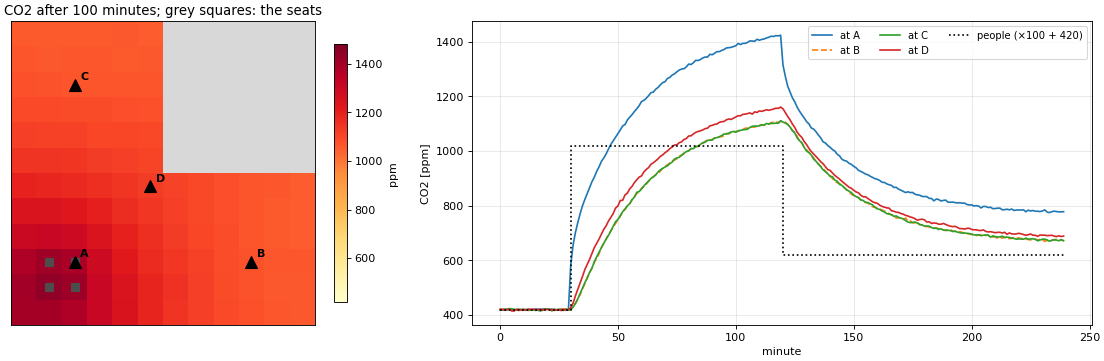

In [ ]:
from kalman.apps import RoomCO2Model

T = 240                                                     # minutes, one step each
minute = np.arange(T)
people = np.where(minute < 30, 0, np.where(minute < 120, 6, 2)).astype(float)

room = RoomCO2Model("A", at=(2, 2))                         # the model, and its own sensor A
spots = {"A": (2, 2), "B": (2, 9), "C": (9, 2), "D": (5, 5)}
every = {"A": 1, "B": 1, "C": 5, "D": 10}                   # minutes between two readings
B, C, D = (room.sensor(name, spots[name], rate=1 / (60 * every[name])) for name in "BCD")

truth = room.add_sensor(B).add_sensor(C).add_sensor(D).sample(T * 60, uk=np.column_stack([people, np.ones(T)]), seed=2)
print(f"{room.n} cells; the CO2 peaks at {truth.xk.max():.0f} ppm")

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
palette = plt.get_cmap("YlOrRd").copy(); palette.set_bad("0.85")          # grey: not the room
image = left.imshow(room.field(truth.xk[100]), origin="lower", cmap=palette, vmin=420, vmax=truth.xk.max())
for r, c in room.seats:
    left.plot(c, r, "s", color="0.3", ms=7)
for name, (r, c) in spots.items():
    left.plot(c, r, "k^", ms=10); left.annotate(name, (c, r), xytext=(5, 4), textcoords="offset points", weight="bold")
left.set_title("CO2 after 100 minutes; grey squares: the seats"); left.set_xticks([]); left.set_yticks([])
fig.colorbar(image, ax=left, label="ppm", shrink=0.85)
for name, (r, c) in spots.items():
    right.plot(minute, truth.xk[:, room.index[(r, c)]], "--" if name == "B" else "-", label=f"at {name}")
right.step(minute, 420 + 100 * people, "k:", where="post", label="people (×100 + 420)")
right.set(xlabel="minute", ylabel="CO2 [ppm]"); right.legend(ncol=3, fontsize=9); right.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Step 2 — The Number of People Is Part of the State

The filter is not told how many people there are. With `count_people=True` the number of occupants
becomes one more component of the state, next to the CO2 of every cell: a number that drifts slowly
as people come and go. The model stays linear, and the CO2 the sensors read tells how many people
breathe in the room.

The sensors do not report together: A and B every minute, C every 5 minutes, D every 10. A sensor
with nothing new gives no number (NaN), and the filter skips it.

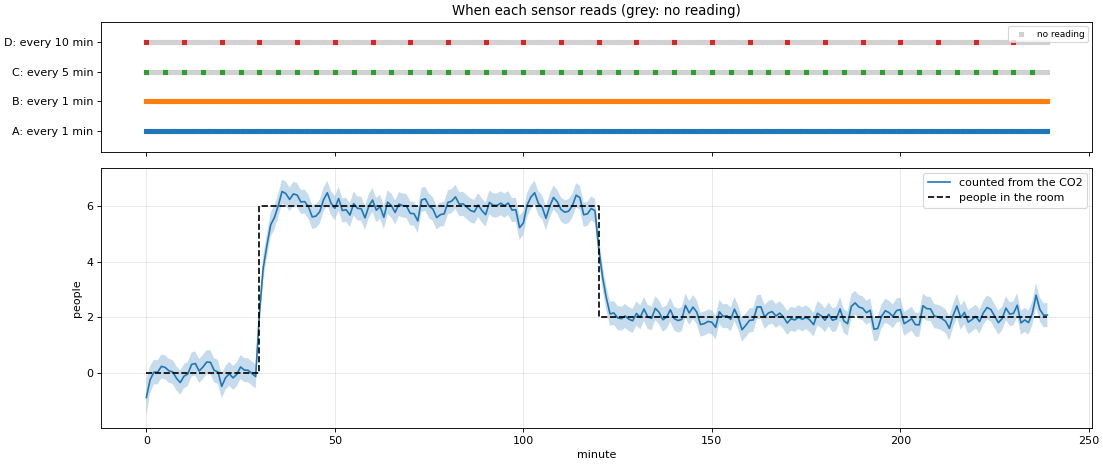

counted at minute 100: 5.4 ± 0.4 people (6 in the room); at minute 200: 2.3 ± 0.4 (2)


In [ ]:
counting = RoomCO2Model("A", at=(2, 2), count_people=True)
Bc, Cc, Dc = (counting.sensor(name, spots[name], rate=1 / (60 * every[name])) for name in "BCD")
counted = counting.add_sensor(Bc).add_sensor(Cc).add_sensor(Dc).filter(truth.zk, uk=np.ones((T, 1)), reset=True)
estimate, sigma = counted.xk[:, -1], np.sqrt(counted.Pk[:, -1, -1])

fig, (top, bottom) = plt.subplots(2, 1, figsize=(14, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
for j, name in enumerate(spots):
    read = ~np.isnan(truth.zk[:, j])
    top.scatter(minute[~read], np.full((~read).sum(), j), marker="s", s=12, color="0.82", label="no reading" if j == 0 else None)
    top.scatter(minute[read], np.full(read.sum(), j), marker="s", s=12, color=f"C{j}")
top.set_yticks(range(4), [f"{name}: every {every[name]} min" for name in spots]); top.set_ylim(-0.7, 3.7)
top.legend(loc="upper right", fontsize=8); top.set_title("When each sensor reads (grey: no reading)")
bottom.fill_between(minute, estimate - sigma, estimate + sigma, alpha=0.25)
bottom.plot(minute, estimate, label="counted from the CO2")
bottom.step(minute, people, "k--", where="post", label="people in the room")
bottom.set(xlabel="minute", ylabel="people"); bottom.legend(); bottom.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"counted at minute 100: {estimate[100]:.1f} ± {sigma[100]:.1f} people (6 in the room); "
      f"at minute 200: {estimate[200]:.1f} ± {sigma[200]:.1f} (2)")

The count follows within a few minutes: that is how long the CO2 breathed out at the seats takes to
reach the sensors.

## Step 3 — A Drifted Sensor Miscounts the People

CO2 sensors drift: B now reads 150 ppm too high. Believed exact, it shows CO2 near B that is not
there; the filter explains it as breath that has spread through the room, and miscounts the people.
Here the count comes out about half a person low: where the error lands depends on where the drifted
sensor stands. B is declared as an *instrument* with a calibration,
`z = gain · c + offset`; the model then has the parameter `B.offset`, and `joint` estimates it with
the CO2 and the count. The other three sensors read the same air without the offset, which is what
makes the drift separable from the people.

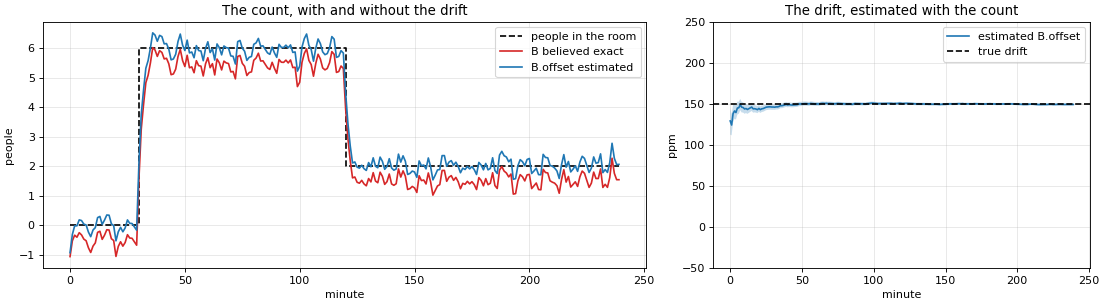

B believed exact     counted at minute 100: 4.9   at minute 200: 1.7   (6 and 2)
B.offset estimated   counted at minute 100: 5.4   at minute 200: 2.3   (6 and 2)


In [ ]:
from kalman.framework import compose

known = np.column_stack([people, np.ones(T)])
drifted = lambda sensor, offset: compose(sensor, name="B").calibrate(gain=1.0, offset=offset)
data = room.add_instrument(drifted(B, 150.0)).add_sensor(C).add_sensor(D).sample(T * 60, uk=known, seed=2)

believed = counting.add_instrument(drifted(Bc, 0.0)).add_sensor(Cc).add_sensor(Dc)   # B believed exact
runs = {"B believed exact": believed.filter(data.zk, uk=np.ones((T, 1)), reset=True),
        "B.offset estimated": believed.joint({"B.offset": (200.0, 0.0)}).filter(data.zk, uk=np.ones((T, 1)), reset=True)}

n = counting.n
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.6, 1]})
left.step(minute, people, "k--", where="post", label="people in the room")
for (name, run), color in zip(runs.items(), ("C3", "C0")):
    left.plot(minute, run.xk[:, n - 1], color=color, label=name)
offset, spread = runs["B.offset estimated"].xk[:, n], np.sqrt(runs["B.offset estimated"].Pk[:, n, n])
right.fill_between(minute, offset - spread, offset + spread, alpha=0.25)
right.plot(minute, offset, label="estimated B.offset"); right.axhline(150, color="k", ls="--", label="true drift")
left.set(xlabel="minute", ylabel="people", title="The count, with and without the drift")
right.set(xlabel="minute", ylabel="ppm", title="The drift, estimated with the count", ylim=(-50, 250))
for ax in (left, right):
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for name, run in runs.items():
    print(f"{name:20s} counted at minute 100: {run.xk[100, n - 1]:.1f}   at minute 200: {run.xk[200, n - 1]:.1f}   (6 and 2)")

## Takeaways

- The room is a mass balance on a grid: mixing, ventilation and breathing. Being linear, it runs as
  matrices on the plain Kalman filter.
- What is not measured can be a state: the number of people is estimated from the CO2, with its
  uncertainty, a few minutes after they arrive or leave.
- Sensors report at their own rates; a missing reading is a NaN that the filter skips.
- A drifted sensor miscounts the people. Declared as an instrument with a calibration, its drift is
  estimated with the count, as long as other sensors read the same air without it.